# UTS DAM — Analisis Data Pariwisata di Bali
**Pengumpulan dan Integrasi Data Pariwisata serta Kondisi Cuaca di Bali**
Sumber: Dataset BPS Provinsi Bali, Open-Meteo Historical Weather API, dan Web Scraping.

## 1. Pendahuluan
**Latar belakang.** Pariwisata adalah sektor utama Bali. Jumlah kunjungan wisatawan berubah mengikuti musim, dan cuaca (suhu, kelembapan, curah hujan) merupakan salah satu faktor yang layak diperiksa. Notebook ini mengumpulkan, membersihkan, dan mengintegrasikan data dari tiga sumber berbeda.

**Tujuan.**
1. Memuat dan merapikan dataset BPS (wide → long, minimal 100 baris).
2. Mengambil data cuaca historis dari Open-Meteo API (JSON → tabel → agregat bulanan).
3. Mengambil data destinasi wisata Bali lewat web scraping.
4. Mengintegrasikan data BPS dan cuaca, lalu mendokumentasikan provenance, metadata, dan etika data.

> **Catatan metodologi:** cuaca diambil di satu titik (Denpasar), sehingga hasilnya adalah *kondisi cuaca di titik Denpasar*, bukan rata-rata seluruh Bali.

## 2. Persiapan Lingkungan

In [1]:
import os, json, time, hashlib, re
from datetime import datetime
from urllib import robotparser
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

# xlrd diperlukan untuk membaca file .xls lama
try:
    import xlrd
except ImportError:
    !pip install -q xlrd
    import xlrd

# --- Google Drive (agar hasil tidak hilang saat sesi Colab berakhir) ---
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/UTS_DAM_PARIWISATA'
DIRS = {
    'raw':       f'{BASE}/data/raw',
    'processed': f'{BASE}/data/processed',
    'metadata':  f'{BASE}/metadata',
    'ethics':    f'{BASE}/ethics',
}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

# --- Konfigurasi ---
BPS_FILE   = f"{DIRS['raw']}/bps_pariwisata.xls"   # upload file .xls BPS ke folder raw dengan nama ini
LAT, LON   = -8.65, 115.2167                       # Denpasar
START_DATE = '2004-01-01'
END_DATE   = '2025-12-31'
EMAIL_KONTAK = 'emailkamu@contoh.ac.id'   # <-- GANTI dengan email kampus/milikmu
HEADERS    = {'User-Agent': f'UTS-DAM-Pariwisata/1.0 (riset akademik; kontak: {EMAIL_KONTAK}) python-requests'}
ACCESS_DATE = datetime.now().strftime('%Y-%m-%d %H:%M:%S')

def md5_file(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b''):
            h.update(chunk)
    return h.hexdigest()

print('Folder proyek:', BASE)
print('Waktu akses  :', ACCESS_DATE)

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/UTS_DAM_PARIWISATA
Waktu akses  : 2026-11-19 02:54:52


## 3. Akuisisi Dataset BPS (Soal 1)
Letakkan file dataset BPS **wisatawan domestik** (`.xls` / `.xlsx` / `.csv`) di folder `data/raw/` di Google Drive. Nama file harus mengandung kata `Domestik`. Notebook akan **berhenti dengan pesan error** jika file tidak ditemukan (tidak ada data tiruan).

Struktur file asli: tiga blok tabel bertumpuk (2004-2012, 2013-2021, 2022-2025), masing-masing diawali baris header `Bulan`, 12 baris bulan, baris total `BALI`, dan baris `Pertumbuhan`. Karena itu file dibaca dengan `header=None` lalu diparsing manual.

In [2]:
import glob, csv, io

kandidat = sorted(p for p in glob.glob(f"{DIRS['raw']}/*") if 'domestik' in os.path.basename(p).lower())
print('Kandidat file BPS domestik:', [os.path.basename(p) for p in kandidat])
if not kandidat:
    raise FileNotFoundError(f"Tidak ada file 'Domestik' di {DIRS['raw']}. Isi folder: {os.listdir(DIRS['raw'])}")
# utamakan format Excel asli bila ada
kandidat.sort(key=lambda p: (os.path.splitext(p)[1].lower() not in ('.xls', '.xlsx'), p))
BPS_FILE = kandidat[0]
ext = os.path.splitext(BPS_FILE)[1].lower()

NA_VALUES = ['-', '', 'NA', 'N/A']
if ext in ('.xls', '.xlsx'):
    READ_PARAMS = dict(sheet_name=0, header=None, dtype=object, na_values=NA_VALUES)
    raw_bps = pd.read_excel(BPS_FILE, **READ_PARAMS)
else:
    # CSV BPS: ada baris judul dengan jumlah kolom berbeda, jadi dibaca dengan modul csv lalu dirapikan
    teks, enc_dipakai = None, None
    for enc in ('utf-8-sig', 'latin-1'):
        try:
            with open(BPS_FILE, encoding=enc) as f:
                teks = f.read(); enc_dipakai = enc; break
        except UnicodeDecodeError:
            continue
    try:
        sep = csv.Sniffer().sniff(teks[:4096], delimiters=',;\t').delimiter
    except csv.Error:
        sep = ','
    baris = list(csv.reader(io.StringIO(teks), delimiter=sep))
    lebar = max(len(b) for b in baris)
    raw_bps = pd.DataFrame([b + [''] * (lebar - len(b)) for b in baris]).replace('', np.nan)
    READ_PARAMS = dict(encoding=enc_dipakai, sep=sep, header=None, dtype='object (parsing manual)', na_values=NA_VALUES)

print('File dipakai  :', os.path.basename(BPS_FILE))
print('Parameter baca:', READ_PARAMS)
print('Dimensi mentah:', raw_bps.shape)
raw_bps.head(20)

Kandidat file BPS domestik: ['Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv']
File dipakai  : Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv
Parameter baca: {'encoding': 'utf-8-sig', 'sep': ',', 'header': None, 'dtype': 'object (parsing manual)', 'na_values': ['-', '', 'NA', 'N/A']}
Dimensi mentah: (53, 10)


,0,1,2,3,4,5,6,7,8,9
0,Kunjungan Wisatawan Domestik ke Bali per Bulan...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Number of Domestic Visitor to Bali by Month, 2...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Bulan,2004,2005,2006,2007,2008,2009,2010,2011,2012
4,Januari,167 106,174 515,202 857,181 266,225 955,264 915,349 575,280 588,333 199
5,Pebruari,133 660,161 808,161 413,144 425,190 792,204 419,238 789,340 508,305 934
6,Maret,118 369,194 411,171 795,161 009,221 181,255 203,202 995,358 313,307 616
7,April,129 730,174 033,192 182,165 509,206 631,247 100,396 898,385 228,331 378
8,Mei,142 186,190 855,188 152,183 736,226 339,289 635,421 369,463 452,525 076
9,Juni,167 718,201 990,204 284,214 957,256 448,304 213,455 456,568 264,569 635


In [3]:
BULAN = {'januari':1,'pebruari':2,'februari':2,'maret':3,'april':4,'mei':5,'juni':6,
         'juli':7,'agustus':8,'september':9,'oktober':10,'nopember':11,'november':11,'desember':12}
NAMA_BULAN = {1:'Januari',2:'Februari',3:'Maret',4:'April',5:'Mei',6:'Juni',
              7:'Juli',8:'Agustus',9:'September',10:'Oktober',11:'November',12:'Desember'}

def to_num(v):
    """Bersihkan angka gaya BPS ('11 961', '1.234.567', '1,234') menjadi numerik."""
    if isinstance(v, str):
        v = v.replace('\xa0', '').replace(' ', '').strip()
        if v in ('', '-'):
            return np.nan
        if re.fullmatch(r'\d{1,3}([.,]\d{3})+', v):
            v = re.sub(r'[.,]', '', v)
    return pd.to_numeric(v, errors='coerce')

def parse_bps_wide(df):
    """Ubah tabel BPS (blok bertumpuk, format lebar) menjadi format panjang.
    Mengembalikan (df_long, df_total) - df_total berisi total tahunan 'BALI' untuk validasi."""
    rows, totals = [], {}
    year_cols = None
    for _, r in df.iterrows():
        first = str(r.iloc[0]).strip()
        if first == 'Bulan':
            # baris header blok: petakan indeks kolom -> tahun (abaikan kolom kosong/non-angka)
            year_cols = {}
            for j, v in enumerate(r.iloc[1:], start=1):
                try:
                    year_cols[j] = int(float(v))
                except (ValueError, TypeError):
                    pass
            continue
        if year_cols is None:
            continue
        key = first.lower()
        if key in BULAN:
            for j, yr in year_cols.items():
                val = to_num(r.iloc[j])
                if pd.notna(val):
                    rows.append({'Tahun': yr, 'Bulan_Angka': BULAN[key], 'Jumlah_Wisatawan': int(val)})
        elif key == 'bali':
            for j, yr in year_cols.items():
                val = to_num(r.iloc[j])
                if pd.notna(val):
                    totals[yr] = int(val)
    out = pd.DataFrame(rows)
    out['Bulan'] = out['Bulan_Angka'].map(NAMA_BULAN)
    out = out[['Tahun','Bulan_Angka','Bulan','Jumlah_Wisatawan']].sort_values(['Tahun','Bulan_Angka']).reset_index(drop=True)
    tot = pd.DataFrame({'Tahun': list(totals), 'Total_BPS': list(totals.values())})
    return out, tot

bps_long, bps_total = parse_bps_wide(raw_bps)
print('Jumlah baris format panjang:', len(bps_long), '(target minimal 100)')
bps_long.head(15)

Jumlah baris format panjang: 264 (target minimal 100)


,Tahun,Bulan_Angka,Bulan,Jumlah_Wisatawan
0,2004,1,Januari,167106
1,2004,2,Februari,133660
2,2004,3,Maret,118369
3,2004,4,April,129730
4,2004,5,Mei,142186
5,2004,6,Juni,167718
6,2004,7,Juli,212463
7,2004,8,Agustus,171034
8,2004,9,September,168420
9,2004,10,Oktober,150827


### Identifikasi dataset

In [4]:
print('Rentang tahun   :', bps_long.Tahun.min(), '-', bps_long.Tahun.max())
print('Jumlah tahun    :', bps_long.Tahun.nunique())
print('Baris per tahun : ', bps_long.groupby('Tahun').size().unique())
print('Missing values  :', bps_long.isna().sum().sum())
print('Duplikat (Tahun,Bulan):', bps_long.duplicated(['Tahun','Bulan_Angka']).sum())
print(bps_long.dtypes)
bps_long.describe()

Rentang tahun   : 2004 - 2025
Jumlah tahun    : 22
Baris per tahun :  [12]
Missing values  : 0
Duplikat (Tahun,Bulan): 0
Tahun                int64
Bulan_Angka          int64
Bulan               object
Jumlah_Wisatawan     int64
dtype: object


,Tahun,Bulan_Angka,Jumlah_Wisatawan
count,264.000000,264.000000,2.640000e+02
mean,2014.500000,6.500000,5.188382e+05
std,6.356339,3.458609,2.694606e+05
min,2004.000000,1.000000,1.019480e+05
25%,2009.000000,3.750000,2.595350e+05
50%,2014.500000,6.500000,5.223980e+05
75%,2020.000000,9.250000,7.328272e+05
max,2025.000000,12.000000,1.287877e+06


In [5]:
# Identifikasi dataset BPS (Soal 1)
ukuran_kb = os.path.getsize(BPS_FILE) / 1024
print('Jenis data        : TERSTRUKTUR (tabular baris-kolom, skema tetap; format spreadsheet/CSV)')
print('Dimensi mentah    :', raw_bps.shape, '(baris x kolom, termasuk judul, header blok, baris total/pertumbuhan)')
print('Dimensi olahan    :', bps_long.shape, '(baris x kolom setelah wide -> long)')
print('Tipe data olahan  :'); print(bps_long.dtypes.to_string())
print('Satuan            : orang (jumlah kunjungan wisatawan domestik per bulan)')
print('Cakupan wilayah   : Provinsi Bali')
print(f'Cakupan waktu     : {bps_long.Tahun.min()}-{bps_long.Tahun.max()} (bulanan)')
print(f'Ukuran berkas     : {ukuran_kb:,.1f} KB ({os.path.basename(BPS_FILE)})')
print('Parameter baca    :', READ_PARAMS)

Jenis data        : TERSTRUKTUR (tabular baris-kolom, skema tetap; format spreadsheet/CSV)
Dimensi mentah    : (53, 10) (baris x kolom, termasuk judul, header blok, baris total/pertumbuhan)
Dimensi olahan    : (264, 4) (baris x kolom setelah wide -> long)
Tipe data olahan  :
Tahun                int64
Bulan_Angka          int64
Bulan               object
Jumlah_Wisatawan     int64
Satuan            : orang (jumlah kunjungan wisatawan domestik per bulan)
Cakupan wilayah   : Provinsi Bali
Cakupan waktu     : 2004-2025 (bulanan)
Ukuran berkas     : 3.5 KB (Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv)
Parameter baca    : {'encoding': 'utf-8-sig', 'sep': ',', 'header': None, 'dtype': 'object (parsing manual)', 'na_values': ['-', '', 'NA', 'N/A']}


### Validasi: jumlah 12 bulan harus sama dengan baris total `BALI` di file BPS

In [6]:
chk = bps_long.groupby('Tahun', as_index=False)['Jumlah_Wisatawan'].sum().merge(bps_total, on='Tahun')
chk['Selisih'] = chk['Jumlah_Wisatawan'] - chk['Total_BPS']
print('Tahun dengan selisih != 0:', (chk['Selisih'] != 0).sum())
chk[chk['Selisih'] != 0]

Tahun dengan selisih != 0: 0


,Tahun,Jumlah_Wisatawan,Total_BPS,Selisih


Tersimpan: bps_clean.csv


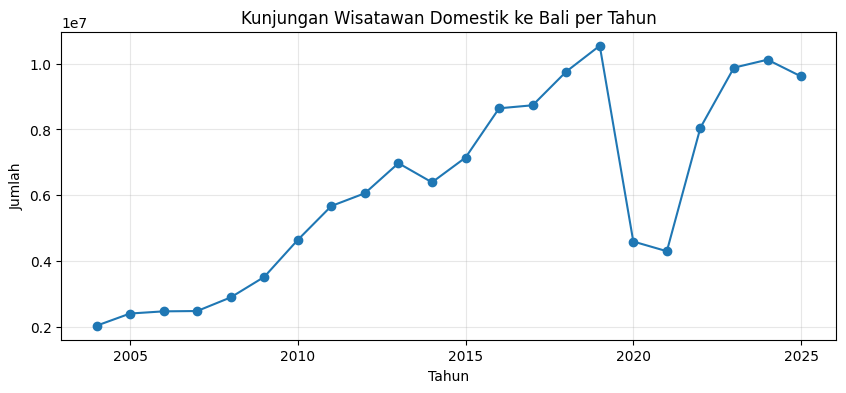

In [7]:
bps_long.to_csv(f"{DIRS['processed']}/bps_clean.csv", index=False, encoding='utf-8')
print('Tersimpan: bps_clean.csv')

# Visualisasi cepat
tren = bps_long.groupby('Tahun')['Jumlah_Wisatawan'].sum()
plt.figure(figsize=(10,4)); tren.plot(marker='o')
plt.title('Kunjungan Wisatawan Domestik ke Bali per Tahun'); plt.ylabel('Jumlah'); plt.grid(alpha=.3); plt.show()

## 4. Data Ethics & License
Bagian ini memeriksa lisensi, PII, dan quasi-identifier. **Isi/verifikasi kolom lisensi dengan membaca ketentuan di situs sumber** sebelum mengumpulkan.

In [8]:
# Pemeriksaan PII / quasi-identifier pada kolom data olahan (bukti untuk checklist)
pii_keywords = ['nama','name','nik','alamat','address','email','telepon','phone','hp','ktp','lahir','birth','usia','umur','gender','kelamin']
pii_hits = {}
for nama, df_ in {'BPS (long)': bps_long}.items():
    hit = [c for c in df_.columns if any(k in c.lower() for k in pii_keywords)]
    pii_hits[nama] = hit
    print(f'{nama}: kolom kolom {list(df_.columns)} -> kolom berpotensi PII/quasi-identifier:', hit if hit else 'tidak ada')

# Bukti lisensi/ketentuan portal (dikutip secara ringkas; BUKA URL-nya sendiri, verifikasi, lalu tempel tangkapan layar/tanggal baca di laporan)
LICENSE_EVIDENCE = {
    'BPS': ('Ketentuan Penggunaan BPS (https://www.bps.go.id/assets/term-of-use): konten tunduk pada hak cipta; '
            'penggunaan wajib memberi kutipan/kredit ke BPS berisi judul konten, tanggal akses, penulis (jika ada), dan tautan langsung ke konten asli. '
            'Sumber data tabel ini: Hasil Survei Dinas Pariwisata Provinsi Bali (tercantum di berkas). '
            f'Dibaca/diverifikasi: {ACCESS_DATE[:10]}'),
    'Open-Meteo': ('Terms (https://open-meteo.com/en/terms): API gratis hanya untuk NON-KOMERSIAL (< 10.000 panggilan/hari, 5.000/jam, 600/menit); '
                   'data berlisensi CC BY 4.0 -> wajib atribusi "Weather data by Open-Meteo.com". '
                   f'Dibaca/diverifikasi: {ACCESS_DATE[:10]}'),
    'Scraping': ('Wikipedia: teks umumnya CC BY-SA 4.0 (cek footer halaman target) -> wajib atribusi + berbagi serupa; '
                 'kebijakan Wikimedia meminta User-Agent deskriptif dengan kontak. '
                 f'Dibaca/diverifikasi: {ACCESS_DATE[:10]}'),
}

BPS (long): kolom kolom ['Tahun', 'Bulan_Angka', 'Bulan', 'Jumlah_Wisatawan'] -> kolom berpotensi PII/quasi-identifier: tidak ada


## 5. Akuisisi API (Soal 3)
Soal meminta **API resmi portal sumber diutamakan** (key disimpan di `.env`/berkas kredensial, bukan di notebook). Urutannya:
- **5a.** Coba WebAPI resmi BPS (`webapi.bps.go.id`, butuh key gratis). Hasilnya (berhasil/gagal + alasan) dicatat sebagai bukti.
- **5b.** Karena BPS tidak menyediakan data cuaca, data cuaca diambil dari API publik **Open-Meteo** (tanpa key) sesuai alternatif yang dibolehkan soal.

Cara menyimpan key: buat berkas `UTS_DAM_PARIWISATA/.env` di Drive berisi satu baris `BPS_API_KEY=isi_key_kamu` (atau pakai Colab *Secrets* dengan nama `BPS_API_KEY`). Daftar key: https://webapi.bps.go.id/developer/register . **Jangan** menulis key di sel notebook dan jangan membagikan `.env`.

In [9]:
# 5a. Upaya API resmi BPS - key dibaca dari Colab Secrets / variabel lingkungan / .env (tidak ditulis di notebook)
def baca_env_file(path):
    out = {}
    if os.path.exists(path):
        with open(path, encoding='utf-8') as f:
            for line in f:
                line = line.strip()
                if line and not line.startswith('#') and '=' in line:
                    k, v = line.split('=', 1)
                    out[k.strip()] = v.strip().strip('"\'')
    return out

def load_secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name) or baca_env_file(f'{BASE}/.env').get(name)

BPS_API_KEY = load_secret('BPS_API_KEY')
BPS_DOMAIN  = '5100'    # kode domain BPS Provinsi Bali
# Pola endpoint mengikuti dokumentasi https://webapi.bps.go.id/developer/ -> SESUAIKAN path bila dokumentasi berbeda
BPS_ENDPOINT = f'https://webapi.bps.go.id/v1/api/list/model/statictable/lang/ind/domain/{BPS_DOMAIN}/keyword/wisatawan/key/'

BPS_API_STATUS = {'dicoba': False, 'http_status': None, 'hasil': None, 'catatan': ''}
if not BPS_API_KEY:
    BPS_API_STATUS.update(hasil='tidak dicoba', catatan='BPS_API_KEY belum diset (.env / Colab Secrets)')
else:
    BPS_API_STATUS['dicoba'] = True
    try:
        r = requests.get(BPS_ENDPOINT + BPS_API_KEY + '/', headers=HEADERS, timeout=30)
        BPS_API_STATUS['http_status'] = r.status_code
        if r.status_code == 200:
            js = r.json()
            with open(f"{DIRS['raw']}/bps_api_list_statictable.json", 'w', encoding='utf-8') as f:
                json.dump(js, f, ensure_ascii=False)       # key tidak ikut tersimpan
            BPS_API_STATUS.update(hasil='berhasil', catatan=f"status API: {js.get('status')}; kunci respons: {list(js.keys())}")
        else:
            BPS_API_STATUS.update(hasil='gagal', catatan=f'HTTP {r.status_code} (403 dapat berarti diblokir Cloudflare dari server cloud / key salah)')
    except Exception as e:
        BPS_API_STATUS.update(hasil='gagal', catatan=f'{type(e).__name__} (pesan disembunyikan agar key tidak bocor)')

BPS_API_STATUS['keputusan'] = ('Data cuaca tidak tersedia di API BPS, sehingga memakai API publik Open-Meteo '
                               '(alternatif yang dibolehkan soal 3).')
with open(f"{DIRS['metadata']}/api_selection.json", 'w', encoding='utf-8') as f:
    json.dump(BPS_API_STATUS, f, indent=2, ensure_ascii=False)
print('Key terbaca     :', 'ya' if BPS_API_KEY else 'tidak')
for k, v in BPS_API_STATUS.items():
    print(f'{k:12}:', v)

Key terbaca     : tidak
dicoba      : False
http_status : None
hasil       : tidak dicoba
catatan     : BPS_API_KEY belum diset (.env / Colab Secrets)
keputusan   : Data cuaca tidak tersedia di API BPS, sehingga memakai API publik Open-Meteo (alternatif yang dibolehkan soal 3).


### 5b. Open-Meteo Historical Weather API (tanpa API key)
Status code ditangani dan ada retry dengan backoff; respons JSON dinormalisasi menjadi tabel.

In [10]:
API_URL = 'https://archive-api.open-meteo.com/v1/archive'
params = {
    'latitude': LAT, 'longitude': LON,
    'start_date': START_DATE, 'end_date': END_DATE,
    'daily': 'temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,weather_code',
    'timezone': 'Asia/Makassar',
}

def fetch_with_retry(url, params=None, max_retry=4, backoff=2, timeout=60):
    last = None
    for attempt in range(1, max_retry + 1):
        try:
            resp = requests.get(url, params=params, headers=HEADERS, timeout=timeout)
            print(f'Percobaan {attempt}: status {resp.status_code}')
            if resp.status_code == 200:
                return resp
            if resp.status_code in (429, 500, 502, 503, 504):   # layak diulang
                time.sleep(backoff ** attempt)
                last = resp
                continue
            resp.raise_for_status()                              # 4xx lain: langsung gagal
        except (requests.ConnectionError, requests.Timeout) as e:
            print('  error jaringan:', e)
            time.sleep(backoff ** attempt)
    raise RuntimeError(f'Gagal mengambil data setelah {max_retry} percobaan (status terakhir: {getattr(last, "status_code", None)})')

resp = fetch_with_retry(API_URL, params)
weather_json = resp.json()
API_FULL_URL = resp.url

with open(f"{DIRS['raw']}/open_meteo.json", 'w', encoding='utf-8') as f:
    json.dump(weather_json, f, ensure_ascii=False)
print('URL     :', API_FULL_URL)
print('Kunci   :', list(weather_json.keys()))
print('Satuan  :', weather_json.get('daily_units'))

Percobaan 1: status 200
URL     : https://archive-api.open-meteo.com/v1/archive?latitude=-8.65&longitude=115.2167&start_date=2004-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Crelative_humidity_2m_mean%2Cprecipitation_sum%2Cweather_code&timezone=Asia%2FMakassar
Kunci   : ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
Satuan  : {'time': 'iso8601', 'temperature_2m_mean': '°C', 'relative_humidity_2m_mean': '%', 'precipitation_sum': 'mm', 'weather_code': 'wmo code'}


### Normalisasi JSON → tabel harian → agregat bulanan

In [11]:
cuaca_harian = pd.DataFrame(weather_json['daily'])
cuaca_harian = cuaca_harian.rename(columns={
    'time': 'Tanggal',
    'temperature_2m_mean': 'Suhu_C',
    'relative_humidity_2m_mean': 'Kelembapan_Persen',
    'precipitation_sum': 'Curah_Hujan_mm',
    'weather_code': 'Kode_Cuaca'})
cuaca_harian['Tanggal'] = pd.to_datetime(cuaca_harian['Tanggal'])
cuaca_harian['Tahun'] = cuaca_harian['Tanggal'].dt.year
cuaca_harian['Bulan_Angka'] = cuaca_harian['Tanggal'].dt.month
print('Baris harian:', len(cuaca_harian), '| Missing:', cuaca_harian.isna().sum().to_dict())

cuaca_bulanan = (cuaca_harian
    .groupby(['Tahun','Bulan_Angka'], as_index=False)
    .agg(Suhu_Rata2_C=('Suhu_C','mean'),
         Kelembapan_Rata2_Persen=('Kelembapan_Persen','mean'),
         Curah_Hujan_Total_mm=('Curah_Hujan_mm','sum'),
         Hari_Hujan=('Curah_Hujan_mm', lambda s: int((s >= 1).sum())),   # hari dengan hujan >= 1 mm
         Jumlah_Hari_Data=('Tanggal','count'))
    .round(2))
print('Baris bulanan:', len(cuaca_bulanan), '(target minimal 30)')
cuaca_bulanan.to_csv(f"{DIRS['processed']}/cuaca_clean.csv", index=False, encoding='utf-8')
cuaca_bulanan.head()

Baris harian: 8036 | Missing: {'Tanggal': 0, 'Suhu_C': 0, 'Kelembapan_Persen': 0, 'Curah_Hujan_mm': 0, 'Kode_Cuaca': 0, 'Tahun': 0, 'Bulan_Angka': 0}
Baris bulanan: 264 (target minimal 30)


,Tahun,Bulan_Angka,Suhu_Rata2_C,Kelembapan_Rata2_Persen,Curah_Hujan_Total_mm,Hari_Hujan,Jumlah_Hari_Data
0,2004,1,26.06,87.65,339.2,29,31
1,2004,2,26.33,86.21,292.3,29,29
2,2004,3,26.25,87.35,345.2,28,31
3,2004,4,26.50,85.77,68.2,22,30
4,2004,5,25.88,86.58,124.0,24,31


## 6. Web Scraping (Soal 4)
Mengambil satu tabel dari halaman statis. Sebelum scraping, `robots.txt` diunduh (dengan User-Agent yang jelas), disimpan sebagai bukti, dan diperiksa dengan `RobotFileParser`. **Jika tidak diizinkan, proses dihentikan.**

> Catatan: `RobotFileParser.read()` bawaan memakai User-Agent `Python-urllib` yang bisa ditolak (403) oleh sebagian situs sehingga hasilnya salah (`False`). Karena itu `robots.txt` diunduh lebih dulu dengan `requests`.

In [12]:
SCRAPE_URL = 'https://id.wikipedia.org/wiki/Pariwisata_di_Bali'

def cek_robots(url, agent='*'):
    p = urlparse(url)
    robots_url = f'{p.scheme}://{p.netloc}/robots.txt'
    r = requests.get(robots_url, headers=HEADERS, timeout=30)
    rp = robotparser.RobotFileParser()
    if r.status_code == 200:
        rp.parse(r.text.splitlines())
        boleh = rp.can_fetch(agent, url)
    elif r.status_code in (404, 410):
        boleh = True                      # tidak ada robots.txt -> tidak ada pembatasan
    else:
        boleh = False                     # 401/403/5xx: anggap tidak boleh (konservatif)
    bukti = {'robots_url': robots_url, 'http_status': r.status_code, 'user_agent_dicek': agent,
             'url_target': url, 'can_fetch': bool(boleh), 'waktu_cek': datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
    return bukti, r.text

robots_evidence, robots_text = cek_robots(SCRAPE_URL)
with open(f"{DIRS['raw']}/robots_{urlparse(SCRAPE_URL).netloc}.txt", 'w', encoding='utf-8') as f:
    f.write(robots_text)
with open(f"{DIRS['metadata']}/robots_check.json", 'w', encoding='utf-8') as f:
    json.dump(robots_evidence, f, indent=2, ensure_ascii=False)

for k, v in robots_evidence.items():
    print(f'{k:16}:', v)
print('\nCuplikan robots.txt:\n', '\n'.join(robots_text.splitlines()[:15]))
if not robots_evidence['can_fetch']:
    raise RuntimeError('robots.txt TIDAK mengizinkan scraping halaman ini. Pilih halaman lain, jangan lanjutkan.')
print('\nHASIL: scraping DIIZINKAN oleh robots.txt')

robots_url      : https://id.wikipedia.org/robots.txt
http_status     : 200
user_agent_dicek: *
url_target      : https://id.wikipedia.org/wiki/Pariwisata_di_Bali
can_fetch       : True
waktu_cek       : 2026-11-19 02:54:58

Cuplikan robots.txt:
 ﻿# robots.txt for http://www.wikipedia.org/ and friends
#
# Please note: There are a lot of pages on this site, and there are
# some misbehaved spiders out there that go _way_ too fast. If you're
# irresponsible, your access to the site may be blocked.
#

# Observed spamming large amounts of https://en.wikipedia.org/?curid=NNNNNN
# and ignoring 429 ratelimit responses, claims to respect robots:
# http://mj12bot.com/
User-agent: MJ12bot
Disallow: /

# advertising-related bots:
User-agent: Mediapartners-Google*

HASIL: scraping DIIZINKAN oleh robots.txt


In [13]:
time.sleep(1)  # jeda sopan sebelum request
resp_web = fetch_with_retry(SCRAPE_URL)
html_path = f"{DIRS['raw']}/scraping_destinasi.html"
with open(html_path, 'w', encoding='utf-8') as f:
    f.write(resp_web.text)

soup = BeautifulSoup(resp_web.text, 'html.parser')
print('Judul halaman :', soup.title.string if soup.title else None)
print('Jumlah <table>:', len(soup.find_all('table')))

Percobaan 1: status 200
Judul halaman : Pariwisata di Bali - Wikipedia bahasa Indonesia, ensiklopedia bebas
Jumlah <table>: 2


In [14]:
# Metode 1: pd.read_html (paling ringkas)
from io import StringIO
tabel_list = pd.read_html(StringIO(resp_web.text))
for i, t in enumerate(tabel_list):
    print(i, t.shape, list(t.columns)[:6])

0 (6, 3) ['Tahun', 'Jumlah Kunjungan', 'Perbandingan (%)']
1 (10, 5) ['Negara', '2012', '2013', '2014', '2015']


In [15]:
# Pilih tabel yang paling relevan (default: tabel terbesar). Ubah indeks jika perlu.
idx = int(np.argmax([len(t) for t in tabel_list]))
destinasi = tabel_list[idx].copy()

# Pembersihan: nama kolom, spasi, referensi [1], baris kosong/duplikat
destinasi.columns = [re.sub(r'\s+', '_', str(c).strip()) for c in destinasi.columns]
for c in destinasi.select_dtypes(include='object').columns:
    destinasi[c] = (destinasi[c].astype(str)
                    .str.replace(r'\[\d+\]', '', regex=True)
                    .str.replace(r'\s+', ' ', regex=True).str.strip())
destinasi = destinasi.replace({'nan': np.nan, '': np.nan}).dropna(how='all').drop_duplicates().reset_index(drop=True)

destinasi.to_csv(f"{DIRS['processed']}/destinasi_clean.csv", index=False, encoding='utf-8')
print('Baris destinasi:', len(destinasi))
destinasi.head(10)

Baris destinasi: 10


,Negara,2012,2013,2014,2015
0,Australia,823821,826385,991923,966869
1,Tiongkok,310904,387533,586300,688469
2,Jepang,191836,208115,217402,228185
3,Malaysia,179941,199232,225572,190381
4,Taiwan,121246,126914,114504,124593
5,Korea Selatan,120982,134452,146008,152866
6,Prancis,115429,125247,128350,131451
7,Singapura,105417,138388,179719,146660
8,Britania Raya,96128,122406,127040,167628
9,Amerika Serikat,94610,105863,111640,133763


### Data Ethics Checklist 9 butir + bukti (Soal 2)
Setiap butir diisi dari **bukti yang dihasilkan notebook** (hasil scan PII, robots check, status API), bukan sekadar jawaban 'Ya'.

In [16]:
# Pindai PII/quasi-identifier pada SEMUA dataset yang dipakai
for nama, df_ in {'Cuaca bulanan': cuaca_bulanan, 'Tabel scraping': destinasi}.items():
    pii_hits[nama] = [c for c in df_.columns if any(k in str(c).lower() for k in pii_keywords)]
pending = [k for k, v in LICENSE_EVIDENCE.items() if v.startswith('ISI')]
if pending:
    print('PERINGATAN: LICENSE_EVIDENCE belum diisi untuk:', pending, '(isi di bagian 4 setelah membaca ketentuan portal)')

ethics = pd.DataFrame([
    [1, 'Sumber data jelas dan dapat ditelusuri',
        'Ya', f"BPS Bali: {os.path.basename(BPS_FILE)}; Open-Meteo: {API_FULL_URL[:70]}...; Web: {SCRAPE_URL}"],
    [2, 'Lisensi/ketentuan portal BPS diperiksa',
        'Ya' if not LICENSE_EVIDENCE['BPS'].startswith('ISI') else 'BELUM', LICENSE_EVIDENCE['BPS']],
    [3, 'Lisensi/ketentuan Open-Meteo diperiksa',
        'Ya' if not LICENSE_EVIDENCE['Open-Meteo'].startswith('ISI') else 'BELUM', LICENSE_EVIDENCE['Open-Meteo']],
    [4, 'Tidak ada PII langsung (nama, NIK, alamat, kontak)',
        'Ya' if not any(pii_hits.values()) else 'PERIKSA', f"Scan nama kolom: {pii_hits}; isi data = agregat jumlah kunjungan bulanan"],
    [5, 'Tidak ada quasi-identifier (usia, gender, lokasi detail, dsb.)',
        'Ya', f"Kolom data olahan: {list(bps_long.columns)}; granularitas terkecil = provinsi x bulan"],
    [6, 'robots.txt diperiksa sebelum scraping',
        'Ya' if robots_evidence['can_fetch'] else 'TIDAK', f"{robots_evidence['robots_url']} status {robots_evidence['http_status']}, can_fetch={robots_evidence['can_fetch']} ({robots_evidence['waktu_cek']})"],
    [7, 'Pengambilan data sopan (jeda, User-Agent jelas, retry terbatas)',
        'Ya', f"time.sleep(1) sebelum scraping; User-Agent: {HEADERS['User-Agent']}; retry maksimal 4x dengan backoff"],
    [8, 'Atribusi/sitasi sumber dicantumkan',
        'Ya', 'metadata/provenance.csv (URL, tanggal akses, lisensi, MD5)'],
    [9, 'Keterbatasan & potensi bias dicatat',
        'Ya', 'Cuaca = titik Denpasar; data = wisatawan domestik; 2020-2021 dipengaruhi COVID-19; data scraping bersumber Wikipedia (bukan sumber resmi)'],
], columns=['No', 'Butir_Checklist', 'Status', 'Bukti'])
ethics.to_csv(f"{DIRS['ethics']}/data_ethics_checklist.csv", index=False, encoding='utf-8')
pd.set_option('display.max_colwidth', 120)
ethics

,No,Butir_Checklist,Status,Bukti
0,1,Sumber data jelas dan dapat ditelusuri,Ya,"BPS Bali: Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv; Open-Meteo: https://archive-api.open-meteo.co..."
1,2,Lisensi/ketentuan portal BPS diperiksa,Ya,Ketentuan Penggunaan BPS (https://www.bps.go.id/assets/term-of-use): konten tunduk pada hak cipta; penggunaan wajib ...
2,3,Lisensi/ketentuan Open-Meteo diperiksa,Ya,"Terms (https://open-meteo.com/en/terms): API gratis hanya untuk NON-KOMERSIAL (< 10.000 panggilan/hari, 5.000/jam, 6..."
3,4,"Tidak ada PII langsung (nama, NIK, alamat, kontak)",Ya,"Scan nama kolom: {'BPS (long)': [], 'Cuaca bulanan': [], 'Tabel scraping': []}; isi data = agregat jumlah kunjungan ..."
4,5,"Tidak ada quasi-identifier (usia, gender, lokasi detail, dsb.)",Ya,"Kolom data olahan: ['Tahun', 'Bulan_Angka', 'Bulan', 'Jumlah_Wisatawan']; granularitas terkecil = provinsi x bulan"
5,6,robots.txt diperiksa sebelum scraping,Ya,"https://id.wikipedia.org/robots.txt status 200, can_fetch=True (2026-11-19 02:54:58)"
6,7,"Pengambilan data sopan (jeda, User-Agent jelas, retry terbatas)",Ya,time.sleep(1) sebelum scraping; User-Agent: UTS-DAM-Pariwisata/1.0 (riset akademik; kontak: emailkamu@contoh.ac.id) ...
7,8,Atribusi/sitasi sumber dicantumkan,Ya,"metadata/provenance.csv (URL, tanggal akses, lisensi, MD5)"
8,9,Keterbatasan & potensi bias dicatat,Ya,Cuaca = titik Denpasar; data = wisatawan domestik; 2020-2021 dipengaruhi COVID-19; data scraping bersumber Wikipedia...


### Estimasi storage 1 tahun (Soal 1)
Rumus: **ukuran berkas x 12 bulan x 1,3** (cadangan 30%).

In [17]:
berkas = {
    'BPS (mentah)':       BPS_FILE,
    'Open-Meteo (JSON)':  f"{DIRS['raw']}/open_meteo.json",
    'Scraping (HTML)':    html_path,
}
BULAN_SNAPSHOT, CADANGAN = 12, 0.30
tabel = pd.DataFrame([{'Berkas': k, 'Ukuran_KB': os.path.getsize(p) / 1024} for k, p in berkas.items()])
tabel['Estimasi_1_tahun_KB'] = tabel['Ukuran_KB'] * BULAN_SNAPSHOT * (1 + CADANGAN)
total = tabel['Estimasi_1_tahun_KB'].sum()
print(tabel.round(1).to_string(index=False))
print(f"\nTOTAL estimasi 1 tahun: {total:,.1f} KB  (= {total/1024:,.2f} MB)")
print("""
Asumsi:
- Setiap bulan seluruh berkas diunduh ulang dan disimpan sebagai snapshot baru (12 snapshot/tahun).
- Ukuran tiap snapshot dianggap sama dengan ukuran sekarang (data historis bertambah lambat).
- Cadangan 30% untuk file olahan (CSV bersih, gabungan), metadata, dan pertumbuhan data.
""")

           Berkas  Ukuran_KB  Estimasi_1_tahun_KB
     BPS (mentah)        3.5                 54.4
Open-Meteo (JSON)      260.0               4055.7
  Scraping (HTML)      160.7               2506.2

TOTAL estimasi 1 tahun: 6,616.3 KB  (= 6.46 MB)

Asumsi:
- Setiap bulan seluruh berkas diunduh ulang dan disimpan sebagai snapshot baru (12 snapshot/tahun).
- Ukuran tiap snapshot dianggap sama dengan ukuran sekarang (data historis bertambah lambat).
- Cadangan 30% untuk file olahan (CSV bersih, gabungan), metadata, dan pertumbuhan data.



## 7. Data Processing
Ringkasan kualitas data ketiga sumber sebelum integrasi.

In [18]:
def profil(nama, df):
    return {'Dataset': nama, 'Baris': len(df), 'Kolom': df.shape[1],
            'Missing': int(df.isna().sum().sum()), 'Duplikat': int(df.duplicated().sum())}

pd.DataFrame([
    profil('BPS (long)', bps_long),
    profil('Cuaca bulanan', cuaca_bulanan),
    profil('Hasil web scraping', destinasi)
])

,Dataset,Baris,Kolom,Missing,Duplikat
0,BPS (long),264,4,0,0
1,Cuaca bulanan,264,7,0,0
2,Hasil web scraping,10,5,0,0


## 8. Data Integration

Integrasi dilakukan dalam dua tingkat sesuai granularitas sumber:
1. **Integrasi bulanan:** BPS dan Open-Meteo digabung berdasarkan `Tahun` + `Bulan_Angka` (one-to-one).
2. **Integrasi tahunan:** BPS dijumlahkan per tahun, lalu digabung dengan hasil web scraping yang memuat jumlah wisatawan mancanegara berdasarkan negara asal per tahun (one-to-one pada `Tahun`).

Hasil scraping tidak dipaksakan masuk ke tabel bulanan karena datanya bersifat tahunan dan memiliki cakupan wisatawan berbeda. Tabel integrasi tahunan menjadi bukti bahwa sumber scraping juga digunakan dalam penggabungan.

In [19]:
# A. Integrasi bulanan: BPS + Open-Meteo
KUNCI_BULANAN = ['Tahun', 'Bulan_Angka']
gabungan = bps_long.merge(
    cuaca_bulanan, on=KUNCI_BULANAN, how='inner', validate='one_to_one'
)
gabungan = gabungan.drop(columns=['Jumlah_Hari_Data'], errors='ignore')

# Validasi integrasi bulanan
cek_bulanan = bps_long.merge(
    cuaca_bulanan[KUNCI_BULANAN], on=KUNCI_BULANAN,
    how='outer', indicator=True
)
tidak_cocok_bulanan = cek_bulanan['_merge'].value_counts().to_dict()

# B. Siapkan hasil scraping menjadi format panjang (Negara, Tahun, Jumlah_Wisman)
# Tabel Wikipedia yang dipilih memiliki kolom Negara dan tahun (mis. 2012-2015).
kolom_tahun_scrape = [
    c for c in destinasi.columns
    if re.fullmatch(r'\d{4}', str(c).strip())
]
if not kolom_tahun_scrape:
    raise ValueError(
        'Tidak ditemukan kolom tahun pada hasil scraping. '
        f'Kolom yang tersedia: {list(destinasi.columns)}'
    )

if 'Negara' not in destinasi.columns:
    raise KeyError(
        "Kolom 'Negara' tidak ditemukan pada hasil scraping. "
        f'Kolom yang tersedia: {list(destinasi.columns)}'
    )

scraping_wide = destinasi[['Negara'] + kolom_tahun_scrape].copy()
for kolom in kolom_tahun_scrape:
    scraping_wide[kolom] = pd.to_numeric(
        scraping_wide[kolom].astype(str).str.replace(r'[^0-9.-]', '', regex=True),
        errors='coerce'
    )

scraping_long = scraping_wide.melt(
    id_vars='Negara',
    value_vars=kolom_tahun_scrape,
    var_name='Tahun',
    value_name='Jumlah_Wisman'
)
scraping_long['Tahun'] = pd.to_numeric(scraping_long['Tahun'], errors='coerce').astype('Int64')
scraping_long['Jumlah_Wisman'] = pd.to_numeric(scraping_long['Jumlah_Wisman'], errors='coerce')
scraping_long = scraping_long.dropna(subset=['Negara', 'Tahun', 'Jumlah_Wisman'])
scraping_long['Tahun'] = scraping_long['Tahun'].astype(int)

# Satu baris per tahun: negara asal menjadi kolom agar dapat digabung dengan BPS tahunan.
scraping_tahunan = (
    scraping_long.pivot_table(
        index='Tahun', columns='Negara', values='Jumlah_Wisman',
        aggfunc='sum'
    )
    .reset_index()
)
scraping_tahunan.columns.name = None
scraping_tahunan = scraping_tahunan.rename(
    columns={c: f'Wisman_{c}' for c in scraping_tahunan.columns if c != 'Tahun'}
)

# Agregasi data BPS bulanan menjadi tahunan.
bps_tahunan = (
    bps_long.groupby('Tahun', as_index=False)
    .agg(Jumlah_Wisatawan_Domestik=('Jumlah_Wisatawan', 'sum'))
)

# C. Integrasi tahunan: BPS + hasil web scraping
gabungan_tahunan = bps_tahunan.merge(
    scraping_tahunan, on='Tahun', how='inner', validate='one_to_one'
)

# Bukti validasi kedua proses integrasi
merge_evidence = {
    'integrasi_bulanan': {
        'metode': "BPS + Open-Meteo: inner join pada Tahun dan Bulan_Angka",
        'baris_bps': int(len(bps_long)),
        'baris_cuaca': int(len(cuaca_bulanan)),
        'baris_gabungan': int(len(gabungan)),
        'duplikat_kunci_gabungan': int(gabungan.duplicated(KUNCI_BULANAN).sum()),
        'anti_join': {k: int(v) for k, v in tidak_cocok_bulanan.items()},
        'missing': int(gabungan.isna().sum().sum())
    },
    'integrasi_tahunan_dengan_scraping': {
        'metode': "BPS tahunan + hasil scraping: inner join pada Tahun",
        'baris_bps_tahunan': int(len(bps_tahunan)),
        'baris_scraping_tahunan': int(len(scraping_tahunan)),
        'baris_gabungan_tahunan': int(len(gabungan_tahunan)),
        'tahun_terintegrasi': sorted(gabungan_tahunan['Tahun'].astype(int).tolist()),
        'kolom_hasil_scraping': [
            c for c in gabungan_tahunan.columns if c.startswith('Wisman_')
        ],
        'duplikat_tahun_gabungan': int(gabungan_tahunan.duplicated(['Tahun']).sum()),
        'missing': int(gabungan_tahunan.isna().sum().sum())
    }
}

for nama, bukti in merge_evidence.items():
    print(f'\\n{nama.upper()}')
    for k, v in bukti.items():
        print(f'{k:38}:', v)

# Pemeriksaan wajib
assert merge_evidence['integrasi_bulanan']['duplikat_kunci_gabungan'] == 0
assert merge_evidence['integrasi_bulanan']['baris_gabungan'] == len(bps_long)
assert merge_evidence['integrasi_bulanan']['anti_join'].get('left_only', 0) == 0
assert merge_evidence['integrasi_bulanan']['anti_join'].get('right_only', 0) == 0
assert len(gabungan_tahunan) > 0, 'Tidak ada tahun yang cocok antara BPS dan hasil scraping.'
assert merge_evidence['integrasi_tahunan_dengan_scraping']['duplikat_tahun_gabungan'] == 0
assert any(c.startswith('Wisman_') for c in gabungan_tahunan.columns)

print('\\nBUKTI: data bulanan BPS-cuaca dan data tahunan BPS-scraping berhasil diintegrasikan.')

# Simpan seluruh hasil integrasi dan bukti validasinya
gabungan.to_csv(
    f"{DIRS['processed']}/data_gabungan.csv", index=False, encoding='utf-8'
)
scraping_long.to_csv(
    f"{DIRS['processed']}/scraping_wisman_long.csv", index=False, encoding='utf-8'
)
gabungan_tahunan.to_csv(
    f"{DIRS['processed']}/data_gabungan_tahunan_scraping.csv",
    index=False, encoding='utf-8'
)
with open(f"{DIRS['metadata']}/validasi_merge.json", 'w', encoding='utf-8') as f:
    json.dump(merge_evidence, f, indent=2, ensure_ascii=False)

print('\\nPreview integrasi tahunan:')
display(gabungan_tahunan.head(10))

\nINTEGRASI_BULANAN
metode                                : BPS + Open-Meteo: inner join pada Tahun dan Bulan_Angka
baris_bps                             : 264
baris_cuaca                           : 264
baris_gabungan                        : 264
duplikat_kunci_gabungan               : 0
anti_join                             : {'both': 264, 'left_only': 0, 'right_only': 0}
missing                               : 0
\nINTEGRASI_TAHUNAN_DENGAN_SCRAPING
metode                                : BPS tahunan + hasil scraping: inner join pada Tahun
baris_bps_tahunan                     : 22
baris_scraping_tahunan                : 4
baris_gabungan_tahunan                : 4
tahun_terintegrasi                    : [2012, 2013, 2014, 2015]
kolom_hasil_scraping                  : ['Wisman_Amerika Serikat', 'Wisman_Australia', 'Wisman_Britania Raya', 'Wisman_Jepang', 'Wisman_Korea Selatan', 'Wisman_Malaysia', 'Wisman_Prancis', 'Wisman_Singapura', 'Wisman_Taiwan', 'Wisman_Tiongkok']
duplikat_tahun_g

,Tahun,Jumlah_Wisatawan_Domestik,Wisman_Amerika Serikat,Wisman_Australia,Wisman_Britania Raya,Wisman_Jepang,Wisman_Korea Selatan,Wisman_Malaysia,Wisman_Prancis,Wisman_Singapura,Wisman_Taiwan,Wisman_Tiongkok
0,2012,6063558,94610,823821,96128,191836,120982,179941,115429,105417,121246,310904
1,2013,6976536,105863,826385,122406,208115,134452,199232,125247,138388,126914,387533
2,2014,6394307,111640,991923,127040,217402,146008,225572,128350,179719,114504,586300
3,2015,7147100,133763,966869,167628,228185,152866,190381,131451,146660,124593,688469


Semua tahun:
Jumlah_Wisatawan           1.00
Suhu_Rata2_C               0.12
Kelembapan_Rata2_Persen   -0.27
Curah_Hujan_Total_mm      -0.09
Hari_Hujan                 0.01
Name: Jumlah_Wisatawan, dtype: float64

Tanpa 2020-2021:
Jumlah_Wisatawan           1.00
Suhu_Rata2_C               0.12
Kelembapan_Rata2_Persen   -0.30
Curah_Hujan_Total_mm      -0.10
Hari_Hujan                 0.02
Name: Jumlah_Wisatawan, dtype: float64


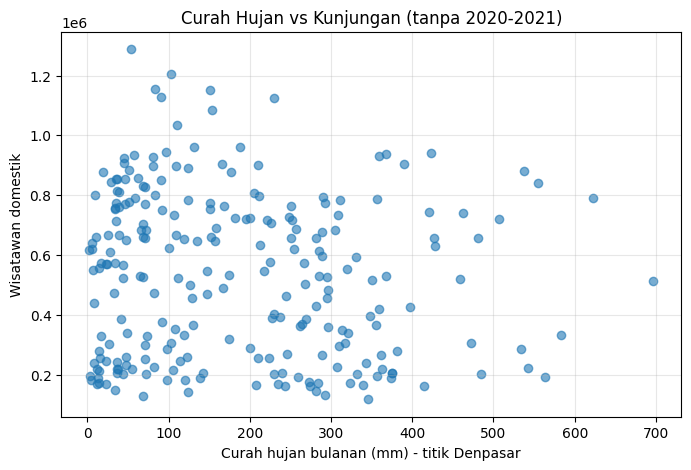

In [20]:
# Korelasi sederhana (hanya eksploratif; tidak membuktikan sebab-akibat)
# Catatan: tahun 2020-2021 (pandemi COVID-19) sangat memengaruhi jumlah wisatawan.
cols = ['Jumlah_Wisatawan','Suhu_Rata2_C','Kelembapan_Rata2_Persen','Curah_Hujan_Total_mm','Hari_Hujan']
print('Semua tahun:');          print(gabungan[cols].corr().round(2)['Jumlah_Wisatawan'])
non_covid = gabungan[~gabungan.Tahun.isin([2020, 2021])]
print('\nTanpa 2020-2021:');   print(non_covid[cols].corr().round(2)['Jumlah_Wisatawan'])

fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(non_covid['Curah_Hujan_Total_mm'], non_covid['Jumlah_Wisatawan'], alpha=.6)
ax.set_xlabel('Curah hujan bulanan (mm) - titik Denpasar'); ax.set_ylabel('Wisatawan domestik')
ax.set_title('Curah Hujan vs Kunjungan (tanpa 2020-2021)'); ax.grid(alpha=.3); plt.show()

## 9. Data Provenance
Mencatat URL sumber, tanggal akses, lisensi, dan checksum MD5 setiap file mentah/olahan.

In [21]:
# Tentukan fungsi hashing yang aman jika file tidak tersedia secara fisik
def dapatkan_hash(path):
    if os.path.exists(path):
        return md5_file(path)
    raise FileNotFoundError(path)

provenance = pd.DataFrame([
    {'Dataset': 'BPS wisatawan domestik bulanan ke Bali 2004-2025',
     'Sumber': 'BPS Provinsi Bali (Hasil Survei Dinas Pariwisata Provinsi Bali)',
     'URL': 'https://bali.bps.go.id/',                      # <-- ganti dengan URL halaman tabel yang kamu unduh
     'Tanggal_Akses': ACCESS_DATE, 'Format': os.path.splitext(BPS_FILE)[1].upper().strip('.'),
     'Lisensi': 'Data publik BPS - wajib mencantumkan sumber (verifikasi di situs BPS)',
     'File': os.path.relpath(BPS_FILE, BASE), 'MD5': dapatkan_hash(BPS_FILE)},
    {'Dataset': 'Open-Meteo Historical Weather (Denpasar)',
     'Sumber': 'Open-Meteo.com', 'URL': API_FULL_URL, 'Tanggal_Akses': ACCESS_DATE, 'Format': 'JSON',
     'Lisensi': 'CC BY 4.0 (non-komersial, atribusi ke Open-Meteo)',
     'File': 'data/raw/open_meteo.json', 'MD5': dapatkan_hash(f"{DIRS['raw']}/open_meteo.json")},
    {'Dataset': 'Destinasi wisata Bali (web scraping)',
     'Sumber': urlparse(SCRAPE_URL).netloc, 'URL': SCRAPE_URL, 'Tanggal_Akses': ACCESS_DATE, 'Format': 'HTML',
     'Lisensi': 'Sesuai ketentuan situs sumber (cek manual)',
     'File': 'data/raw/scraping_destinasi.html', 'MD5': dapatkan_hash(html_path)},
    {'Dataset': 'Data gabungan BPS + cuaca', 'Sumber': 'Turunan dari dua sumber di atas', 'URL': '-',
     'Tanggal_Akses': ACCESS_DATE, 'Format': 'CSV', 'Lisensi': 'Mengikuti lisensi sumber',
     'File': 'data/processed/data_gabungan.csv', 'MD5': dapatkan_hash(f"{DIRS['processed']}/data_gabungan.csv")},
])
provenance.to_csv(f"{DIRS['metadata']}/provenance.csv", index=False, encoding='utf-8')

data_dictionary = pd.DataFrame([
    ['Tahun','int','Tahun kalender','BPS'],
    ['Bulan_Angka','int','Nomor bulan (1-12)','BPS'],
    ['Bulan','str','Nama bulan (Indonesia)','BPS'],
    ['Jumlah_Wisatawan','int','Kunjungan wisatawan domestik ke Bali per bulan (orang)','BPS'],
    ['Suhu_Rata2_C','float','Rata-rata suhu udara 2 m harian dalam sebulan (°C), titik Denpasar','Open-Meteo'],
    ['Kelembapan_Rata2_Persen','float','Rata-rata kelembapan relatif harian dalam sebulan (%)','Open-Meteo'],
    ['Curah_Hujan_Total_mm','float','Total curah hujan sebulan (mm)','Open-Meteo'],
    ['Hari_Hujan','int','Jumlah hari dengan curah hujan >= 1 mm','Open-Meteo (turunan)'],
], columns=['Kolom','Tipe','Deskripsi','Sumber'])
data_dictionary.to_csv(f"{DIRS['metadata']}/data_dictionary.csv", index=False, encoding='utf-8')

metadata_gabungan = {
    'judul': 'Data gabungan kunjungan wisatawan domestik Bali dan cuaca bulanan Denpasar',
    'dibuat': ACCESS_DATE,
    'jumlah_baris': int(len(gabungan)), 'jumlah_kolom': int(gabungan.shape[1]),
    'rentang_waktu': [int(gabungan.Tahun.min()), int(gabungan.Tahun.max())],
    'kunci_penggabungan': ['Tahun','Bulan_Angka'],
    'koordinat_cuaca': {'lokasi': 'Denpasar', 'lat': LAT, 'lon': LON},
    'keterbatasan': ['Cuaca hanya mewakili titik Denpasar, bukan seluruh Bali',
                     'Data BPS hanya wisatawan domestik',
                     'Tahun 2020-2021 dipengaruhi pandemi COVID-19'],
    'kolom': list(gabungan.columns),
    'validasi_merge': merge_evidence,
    'robots_check': robots_evidence,
    'api_bps': BPS_API_STATUS,
}
with open(f"{DIRS['metadata']}/metadata_gabungan.json", 'w', encoding='utf-8') as f:
    json.dump(metadata_gabungan, f, ensure_ascii=False, indent=2)
provenance[['Dataset','Tanggal_Akses','File','MD5']]

,Dataset,Tanggal_Akses,File,MD5
0,BPS wisatawan domestik bulanan ke Bali 2004-2025,2026-11-19 02:54:52,"data/raw/Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv",c0be2f368c6339e80ee7128a9ea6f55f
1,Open-Meteo Historical Weather (Denpasar),2026-11-19 02:54:52,data/raw/open_meteo.json,6746764d377ccee9d9f633a7d212aac0
2,Destinasi wisata Bali (web scraping),2026-11-19 02:54:52,data/raw/scraping_destinasi.html,947bdb0c8423c880c4c4a01b5e4dbb78
3,Data gabungan BPS + cuaca,2026-11-19 02:54:52,data/processed/data_gabungan.csv,c4348977ad8e363a46cf5f06af8294e1


## 10. Hasil dan Kesimpulan

In [22]:
print('Dataset akhir :', gabungan.shape)
print('Periode       :', gabungan.Tahun.min(), '-', gabungan.Tahun.max())
print('File keluaran :')
for root, _, files in os.walk(BASE):
    for fn in sorted(files):
        print(' -', os.path.relpath(os.path.join(root, fn), BASE))

Dataset akhir : (264, 8)
Periode       : 2004 - 2025
File keluaran :
 - README.md
 - data/raw/Banyaknya Wisatawan Domestik Bulanan ke Bali, 2004-2025.csv
 - data/raw/Banyaknya Wisatawan Mancanegara Bulanan ke Bali, 1982-2008.csv
 - data/raw/Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv
 - data/raw/Banyaknya Wisatawan Mancanegara yang Datang Langsung ke Bali Menurut Kebangsaan 2019-2024.xlsx
 - data/raw/open_meteo.json
 - data/raw/robots_id.wikipedia.org.txt
 - data/raw/scraping_destinasi.html
 - data/processed/bps_clean.csv
 - data/processed/cuaca_clean.csv
 - data/processed/data_gabungan.csv
 - data/processed/data_gabungan_tahunan_scraping.csv
 - data/processed/destinasi_clean.csv
 - data/processed/scraping_wisman_long.csv
 - metadata/api_selection.json
 - metadata/data_dictionary.csv
 - metadata/metadata_gabungan.json
 - metadata/provenance.csv
 - metadata/robots_check.json
 - metadata/validasi_merge.json
 - ethics/data_ethics_checklist.csv


**Kesimpulan (isi dengan angka dari hasil run-mu sendiri):**
1. Dataset BPS domestik dibaca dengan parameter eksplisit, diidentifikasi (terstruktur, ___ baris x ___ kolom mentah, satuan orang, Provinsi Bali, 2004-2025), dan diubah ke format panjang ___ baris. Total bulanan cocok dengan baris total BPS. Estimasi storage 1 tahun: ___ KB.
2. Lisensi/ketentuan BPS, Open-Meteo, dan Wikipedia diperiksa; hasil pemeriksaan PII/quasi-identifier dicatat dalam checklist 9 butir di `ethics/data_ethics_checklist.csv`.
3. API resmi BPS dicoba (hasil: ___, lihat `metadata/api_selection.json`); cuaca diambil dari Open-Meteo dan dinormalisasi menjadi ___ baris bulanan.
4. `robots.txt` diperiksa sebelum scraping; satu tabel Wikipedia berisi jumlah wisatawan mancanegara berdasarkan negara asal dan tahun berhasil diambil serta dibersihkan.
5. Integrasi bulanan BPS dan cuaca dilakukan dengan kunci `Tahun` + `Bulan_Angka`, menghasilkan ___ baris. Hasil scraping juga digunakan dalam integrasi tahunan: data BPS dijumlahkan per tahun, lalu digabung dengan data wisatawan mancanegara hasil scraping berdasarkan `Tahun`. Hasilnya ___ tahun yang cocok. Bukti kedua integrasi tersimpan di `metadata/validasi_merge.json`.
6. Keterbatasan: data cuaca hanya mewakili titik Denpasar; data BPS mencakup wisatawan domestik sedangkan scraping mencakup wisatawan mancanegara; data scraping hanya tersedia untuk tahun tertentu (sesuai tabel sumber). Karena cakupan dan granularitas berbeda, hasil scraping digabung pada tingkat tahunan dan tidak dicampur ke baris bulanan. Korelasi bukan bukti sebab-akibat; 2020-2021 dipengaruhi COVID-19.

In [23]:
# README.md proyek (sesuai struktur folder rancangan)
readme = f"""# UTS DAM - Analisis Data Pariwisata Bali

Integrasi dataset BPS (wisatawan domestik bulanan ke Bali 2004-2025), data cuaca Open-Meteo (titik Denpasar), dan satu tabel hasil web scraping.

## Struktur
- data/raw/        : berkas mentah (BPS, open_meteo.json, scraping_destinasi.html, robots.txt)
- data/processed/  : bps_clean.csv, cuaca_clean.csv, destinasi_clean.csv, data_gabungan.csv, scraping_wisman_long.csv, data_gabungan_tahunan_scraping.csv
- metadata/        : provenance.csv, data_dictionary.csv, metadata_gabungan.json, robots_check.json, api_selection.json, validasi_merge.json (bukti integrasi bulanan dan tahunan)
- ethics/          : data_ethics_checklist.csv

## Menjalankan
1. Letakkan CSV/XLS BPS domestik di data/raw/ (nama berkas memuat kata 'Domestik').
2. (Opsional) buat .env berisi BPS_API_KEY=... atau pakai Colab Secrets. Jangan commit .env.
3. Jalankan semua sel UTS_DAM_Pariwisata.ipynb dari atas.

## Atribusi
- Data: BPS Provinsi Bali (Hasil Survei Dinas Pariwisata Provinsi Bali).
- Weather data by Open-Meteo.com (CC BY 4.0).
- Tabel scraping: Wikipedia (CC BY-SA 4.0).

Dibuat: {ACCESS_DATE}
"""
with open(f"{BASE}/README.md", 'w', encoding='utf-8') as f:
    f.write(readme)
print('README.md tersimpan di', BASE)

README.md tersimpan di /content/drive/MyDrive/UTS_DAM_PARIWISATA
